<a href="https://colab.research.google.com/github/hungpham9871/Final-Assgignment--AI-Analysis/blob/main/Copy_of_BigData_PySpark.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# BÀI TẬP THỰC HÀNH: CƠ SỞ PHÂN TÍCH DỮ LIỆU LỚN DÙNG PYSPARK
*Môn: Phân tích dữ liệu lớn trong đầu tư và kinh doanh*

Notebook này làm theo đúng thứ tự và số th
├── BigData_PySpark.ipynb
├── report.pdf
├── README.md
└── dataset/   (hoặc Datasets/ – đặt các file dữ liệu ở đây)
```
ứ tự câu (1 → 66) trong tài liệu hướng dẫn PDF.

**Cấu trúc thư mục yêu cầu:**
```
MSSV_HoTen_BigDataPySpark/


In [ ]:
import os
from pathlib import Path

# Định nghĩa đường dẫn thư mục chứa dữ liệu trên Google Colab
DATA_DIR = Path("/content")

# Đặt tên file Fifa 2018 đúng thực tế trên Colab
file_name = "Fifa2018_dataset.csv"
file_path = DATA_DIR / file_name
file_name_2="Movie ratings.csv"
file_path_2 = DATA_DIR / file_name_2
file_name_3= "people.csv"
file_path_3= DATA_DIR / file_name_3
file_name_4= "Complete Shakespeare.txt"
file_path_4 = DATA_DIR / file_name_4

print(f"Thư mục dữ liệu đã cấu hình: {DATA_DIR}")
print(f"File FIFA 2018 đang sử dụng: {file_path}")

Thư mục dữ liệu đã cấu hình: /content
File FIFA 2018 đang sử dụng: /content/Fifa2018_dataset.csv


# BÀI 1. LÀM QUEN VỚI APACHE SPARK VÀ PYSPARK

## Bài 1.1. Khởi tạo Spark

In [ ]:
from pyspark.sql import SparkSession, functions as F

spark = SparkSession.builder \
    .appName('BigDataFundamentals') \
    .master('local[*]') \
    .getOrCreate()

sc = spark.sparkContext

**Câu 1 – 5**

In [ ]:
import sys
import os

print('1. Spark version      :', spark.version)                       # câu 1
print('2. Python version     :', sys.version.split()[0])              # câu 2
print('3. Master             :', sc.master)                           # câu 3
print('4. Số core có thể dùng:', sc.defaultParallelism,
      '(os.cpu_count =', os.cpu_count(), ')')                        # câu 4
print('5. Tên ứng dụng       :', sc.appName)                         # câu 5

1. Spark version      : 4.0.4
2. Python version     : 3.13.16
3. Master             : local[*]
4. Số core có thể dùng: 2 (os.cpu_count = 2 )
5. Tên ứng dụng       : BigDataFundamentals


**Câu hỏi: SparkSession và SparkContext khác nhau như thế nào?**
- `SparkContext` (`sc`) là điểm vào cũ (low-level) của Spark, kết nối với cluster và dùng để tạo **RDD**, broadcast variable, accumulator.
- `SparkSession` (`spark`) là điểm vào thống nhất từ Spark 2.0, gói gọn `SparkContext`, `SQLContext`, `HiveContext`; dùng để tạo **DataFrame**, chạy **Spark SQL**, đọc/ghi dữ liệu. Có thể lấy SparkContext qua `spark.sparkContext`.

**Câu hỏi: `local[*]` có ý nghĩa gì?**
Chạy Spark ở chế độ **local** (một máy, không cần cluster) và dùng **tất cả các core CPU** có sẵn làm số luồng xử lý song song (`local[2]` = 2 luồng, `local` = 1 luồng).

## Bài 1.2. Parallel Collection

In [ ]:
numbers = list(range(1, 101))
numbers_rdd = sc.parallelize(numbers)                 # câu 6: danh sách -> RDD

print('7.  Số phần tử       :', numbers_rdd.count())  # câu 7
print('8.  10 phần tử đầu   :', numbers_rdd.take(10)) # câu 8
print('9.  Tổng 1..100      :', numbers_rdd.sum())    # câu 9  (= 5050)
print('10. Max / Min        :', numbers_rdd.max(), '/', numbers_rdd.min())  # câu 10

7.  Số phần tử       : 100
8.  10 phần tử đầu   : [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]
9.  Tổng 1..100      : 5050
10. Max / Min        : 100 / 1


## Bài 1.3. Map và Filter

In [ ]:
squares = numbers_rdd.map(lambda x: x * x)                       # câu 11
div3    = numbers_rdd.filter(lambda x: x % 3 == 0)               # câu 12
div5    = numbers_rdd.filter(lambda x: x % 5 == 0)               # câu 13
div15   = numbers_rdd.filter(lambda x: x % 3 == 0 and x % 5 == 0)  # câu 14

print('11. Bình phương (10 đầu):', squares.take(10))
print('12. Chia hết cho 3      :', div3.collect())
print('13. Chia hết cho 5      :', div5.collect())
print('14. Chia hết cho 3 và 5 :', div15.collect())

11. Bình phương (10 đầu): [1, 4, 9, 16, 25, 36, 49, 64, 81, 100]
12. Chia hết cho 3      : [3, 6, 9, 12, 15, 18, 21, 24, 27, 30, 33, 36, 39, 42, 45, 48, 51, 54, 57, 60, 63, 66, 69, 72, 75, 78, 81, 84, 87, 90, 93, 96, 99]
13. Chia hết cho 5      : [5, 10, 15, 20, 25, 30, 35, 40, 45, 50, 55, 60, 65, 70, 75, 80, 85, 90, 95, 100]
14. Chia hết cho 3 và 5 : [15, 30, 45, 60, 75, 90]


**Câu hỏi: Khác nhau giữa `rdd.map(...)` và hàm `map(...)` của Python?**

| | `rdd.map(f)` (Spark) | `map(f, iterable)` (Python) |
|---|---|---|
| Thực thi | **Phân tán**, chạy song song trên các partition/executor | Tuần tự trên 1 tiến trình |
| Đánh giá | **Lazy** – trả về RDD mới, chỉ chạy khi gặp action | Trả về iterator (cũng lười nhưng chỉ trong 1 máy) |
| Kết quả | RDD (dữ liệu phân tán, chịu lỗi nhờ lineage) | Đối tượng `map` trong bộ nhớ 1 máy |
| Quy mô | Dữ liệu lớn hơn RAM 1 máy | Giới hạn bởi RAM 1 máy |

## Bài 1.4. Transformation, Action và Lazy Evaluation

In [ ]:
rdd = sc.parallelize(range(1, 1000000))
result = rdd.filter(lambda x: x % 2 == 0).map(lambda x: x * x)

# Câu 15: Chưa tính toán – result chỉ là 'kế hoạch' (lineage)
print('15. Kiểu của result:', type(result))
print(result.toDebugString().decode())

15. Kiểu của result: <class 'pyspark.core.rdd.PipelinedRDD'>
(2) PythonRDD[71] at RDD at PythonRDD.scala:57 []
 |  ParallelCollectionRDD[70] at readRDDFromFile at PythonRDD.scala:298 []


In [ ]:
import time
import pandas as pd
import matplotlib.pyplot as plt
import string

# Câu 16: take(10) là ACTION -> Spark mới thực sự chạy job
t0 = time.time()
print('16. take(10):', result.take(10))
print(f'    Thời gian: {time.time() - t0:.3f}s')

16. take(10): [4, 16, 36, 64, 100, 144, 196, 256, 324, 400]
    Thời gian: 0.124s


**Câu 17 – Xác định transformation và action**
- **Transformation** (lazy, trả về RDD mới): `parallelize` (tạo RDD), `filter(...)`, `map(...)`.
- **Action** (kích hoạt tính toán, trả kết quả về driver): `take(10)`, `count()`, `collect()`, `sum()`...

**Câu 18 – Lazy evaluation**
Spark **không chạy ngay** khi gọi transformation mà chỉ ghi lại chuỗi phép biến đổi (DAG/lineage). Chỉ khi gặp một *action* thì Spark mới tối ưu DAG rồi thực thi. Lợi ích: (1) gộp nhiều bước thành một stage, tránh tính dư; (2) `take(10)` chỉ cần xử lý vừa đủ dữ liệu thay vì cả 1 triệu phần tử; (3) tiết kiệm bộ nhớ, tự phục hồi khi lỗi nhờ lineage.

# BÀI 2. XỬ LÝ DỮ LIỆU PHÂN TÁN VỚI RDD

## Bài 2.1. Đọc dữ liệu Shakespeare

In [ ]:
text_rdd = sc.textFile(str(DATA_DIR / 'Complete Shakespeare.txt'))

print('19. Số dòng       :', text_rdd.count())
print('20. 10 dòng đầu   :')
for line in text_rdd.take(10):
    print('   ', repr(line))
print('21. Số partition  :', text_rdd.getNumPartitions())

19. Số dòng       : 18014
20. 10 dòng đầu   :
    'The Project Gutenberg EBook of The Complete Works of William Shakespeare, by'
    'William Shakespeare'
    ''
    'This eBook is for the use of anyone anywhere at no cost and with'
    'almost no restrictions whatsoever.  You may copy it, give it away or'
    're-use it under the terms of the Project Gutenberg License included'
    'with this eBook or online at www.gutenberg.org'
    ''
    '** This is a COPYRIGHTED Project Gutenberg eBook, Details Below **'
    '**     Please follow the copyright guidelines in this file.     **'
21. Số partition  : 2


In [ ]:
# Câu 22: repartition / coalesce với 2, 4, 8 partition
for n in (2, 4, 8):
    r = text_rdd.repartition(n)          # có shuffle: tăng hoặc giảm
    print(f'repartition({n}) -> {r.getNumPartitions()} partitions | count = {r.count()}')

for n in (2, 4, 8):
    c = text_rdd.coalesce(n)             # không shuffle: chỉ nên GIẢM số partition
    print(f'coalesce({n})    -> {c.getNumPartitions()} partitions')

# Kích thước từng partition (nhìn mức độ cân bằng tải)
print('Số dòng mỗi partition (repartition 4):',
      text_rdd.repartition(4).glom().map(len).collect())

repartition(2) -> 2 partitions | count = 18014
repartition(4) -> 4 partitions | count = 18014
repartition(8) -> 8 partitions | count = 18014
coalesce(2)    -> 2 partitions
coalesce(4)    -> 2 partitions
coalesce(8)    -> 2 partitions
Số dòng mỗi partition (repartition 4): [4490, 4510, 4510, 4504]


**Câu hỏi: Partition có vai trò gì trong xử lý song song?**
Partition là **đơn vị chia nhỏ dữ liệu** của RDD/DataFrame. Mỗi partition được xử lý bởi **một task** độc lập; số task chạy đồng thời tối đa bằng số core. Quá ít partition → không tận dụng hết core; quá nhiều → overhead lập lịch lớn. `repartition()` thay đổi số partition (có shuffle), `coalesce()` chỉ gộp bớt partition (không shuffle, rẻ hơn).

## Bài 2.2. Word Count

In [ ]:
words      = text_rdd.flatMap(lambda line: line.split())     # câu 23
pairs      = words.map(lambda w: (w, 1))                     # câu 24
word_count = pairs.reduceByKey(lambda a, b: a + b)           # câu 25

print('23. Một số từ  :', words.take(10))
print('24. Cặp (w,1)  :', pairs.take(5))
print('25. Số từ khác nhau:', word_count.count())

print('26. Top 20 từ xuất hiện nhiều nhất:')                  # câu 26
for w, c in word_count.takeOrdered(20, key=lambda x: -x[1]):
    print(f'   {w:<12}{c}')

23. Một số từ  : ['The', 'Project', 'Gutenberg', 'EBook', 'of', 'The', 'Complete', 'Works', 'of', 'William']
24. Cặp (w,1)  : [('The', 1), ('Project', 1), ('Gutenberg', 1), ('EBook', 1), ('of', 1)]
25. Số từ khác nhau: 19545
26. Top 20 từ xuất hiện nhiều nhất:
   the         3109
   I           2888
   and         2403
   to          2295
   of          2060
   a           1643
   my          1531
   you         1495
   in          1434
   that        1221
   is          1119
   not         1030
   with        923
   And         907
   his         867
   for         841
   your        835
   have        805
   be          804
   me          776


## Bài 2.3. Làm sạch văn bản

In [ ]:
# Danh sách stopwords tiếng Anh thông dụng (broadcast để dùng cho mọi executor)
STOPWORDS = set('''a about above after again against all am an and any are as at be because been before
being below between both but by can did do does doing down during each few for from further had has have
having he her here hers herself him himself his how i if in into is it its itself just me more most my
myself no nor not now of off on once only or other our ours ourselves out over own same she should so some
such than that the their theirs them themselves then there these they this those through to too under until
up very was we were what when where which while who whom why will with you your yours yourself yourselves
thou thee thy thine hath doth art shall unto upon'''.split())
bc_stop = sc.broadcast(STOPWORDS)

PUNCT_TABLE = str.maketrans('', '', string.punctuation + '“”‘’—–…')

lower_words = words.map(lambda w: w.lower())                              # câu 27
no_punct    = lower_words.map(lambda w: w.translate(PUNCT_TABLE)) \
                         .filter(lambda w: len(w) > 0)                    # câu 28
min3        = no_punct.filter(lambda w: len(w) >= 3)                      # câu 29
no_stop     = min3.filter(lambda w: w not in bc_stop.value)               # câu 30

print('27. Chữ thường        :', lower_words.take(8))
print('28. Bỏ dấu câu        :', no_punct.take(8))
print('29. Bỏ từ < 3 ký tự   :', min3.take(8))
print('30. Bỏ stopwords      :', no_stop.take(8))
print('Số từ (tokens): raw =', words.count(), '| sau làm sạch =', no_stop.count())

27. Chữ thường        : ['the', 'project', 'gutenberg', 'ebook', 'of', 'the', 'complete', 'works']
28. Bỏ dấu câu        : ['the', 'project', 'gutenberg', 'ebook', 'of', 'the', 'complete', 'works']
29. Bỏ từ < 3 ký tự   : ['the', 'project', 'gutenberg', 'ebook', 'the', 'complete', 'works', 'william']
30. Bỏ stopwords      : ['project', 'gutenberg', 'ebook', 'complete', 'works', 'william', 'shakespeare', 'william']
Số từ (tokens): raw = 128576 | sau làm sạch = 63195


In [ ]:
# Câu 31: 20 từ phổ biến nhất sau làm sạch
clean_count = no_stop.map(lambda w: (w, 1)).reduceByKey(lambda a, b: a + b)
top20_clean = clean_count.takeOrdered(20, key=lambda x: -x[1])
for w, c in top20_clean:
    print(f'{w:<12}{c}')

love        412
sir         408
good        400
well        388
antony      376
would       348
come        320
lord        310
enter       285
first       275
let         271
make        265
rosalind    264
one         263
know        262
cleopatra   261
ill         258
caesar      255
say         253
man         248


## Bài 2.4. Phân tích chiều dài từ

,Nhóm,Số lượng
0,1-4 ký tự,21455
1,5-8 ký tự,36355
2,>= 9 ký tự,5385


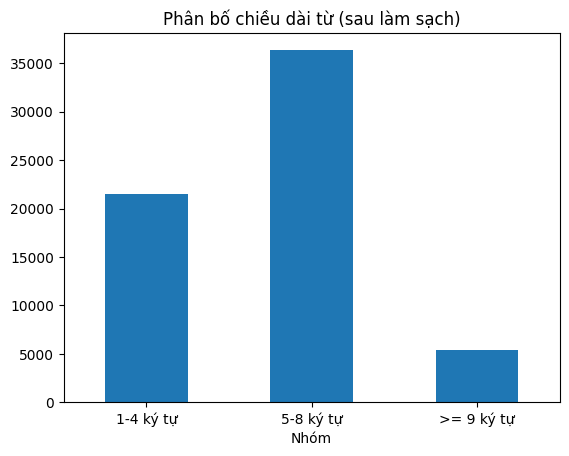

In [ ]:
def length_group(w):
    n = len(w)
    return '1-4 ký tự' if n <= 4 else ('5-8 ký tự' if n <= 8 else '>= 9 ký tự')

length_counts = no_stop.map(lambda w: (length_group(w), 1)).reduceByKey(lambda a, b: a + b).collect()
len_df = (pd.DataFrame(length_counts, columns=['Nhóm', 'Số lượng'])
            .sort_values('Nhóm').reset_index(drop=True))
display(len_df)

len_df.plot.bar(x='Nhóm', y='Số lượng', legend=False, rot=0, title='Phân bố chiều dài từ (sau làm sạch)')
plt.show()

## Bài 2.5. Transformation nâng cao

In [ ]:
# Câu 32: map, flatMap, filter, distinct, reduceByKey, sortByKey – ví dụ trên dữ liệu nhỏ
sample = sc.parallelize(['to be or not to be', 'that is the question', 'to be is to do'])

print('map      :', sample.map(lambda s: s.upper()).collect())
print('   -> 1 phần tử vào = 1 phần tử ra (3 dòng -> 3 dòng).')

print('flatMap  :', sample.flatMap(lambda s: s.split()).collect())
print('   -> 1 phần tử vào = 0..n phần tử ra, kết quả được "làm phẳng" thành danh sách từ.')

print('filter   :', sample.flatMap(lambda s: s.split()).filter(lambda w: len(w) > 2).collect())
print('   -> chỉ giữ các phần tử thỏa điều kiện.')

print('distinct :', sorted(sample.flatMap(lambda s: s.split()).distinct().collect()))
print('   -> loại phần tử trùng (có shuffle).')

wc = sample.flatMap(lambda s: s.split()).map(lambda w: (w, 1)).reduceByKey(lambda a, b: a + b)
print('reduceByKey:', wc.collect())
print('   -> gộp giá trị cùng key, có combine cục bộ trước khi shuffle.')

print('sortByKey :', wc.sortByKey().collect())
print('   -> sắp xếp cặp (key, value) theo key (tăng dần; ascending=False để giảm dần).')
print('   Sắp xếp theo value :', wc.map(lambda kv: (kv[1], kv[0])).sortByKey(ascending=False).collect())

map      : ['TO BE OR NOT TO BE', 'THAT IS THE QUESTION', 'TO BE IS TO DO']
   -> 1 phần tử vào = 1 phần tử ra (3 dòng -> 3 dòng).
flatMap  : ['to', 'be', 'or', 'not', 'to', 'be', 'that', 'is', 'the', 'question', 'to', 'be', 'is', 'to', 'do']
   -> 1 phần tử vào = 0..n phần tử ra, kết quả được "làm phẳng" thành danh sách từ.
filter   : ['not', 'that', 'the', 'question']
   -> chỉ giữ các phần tử thỏa điều kiện.
distinct : ['be', 'do', 'is', 'not', 'or', 'question', 'that', 'the', 'to']
   -> loại phần tử trùng (có shuffle).
reduceByKey: [('to', 4), ('question', 1), ('be', 3), ('or', 1), ('not', 1), ('that', 1), ('is', 2), ('the', 1), ('do', 1)]
   -> gộp giá trị cùng key, có combine cục bộ trước khi shuffle.
sortByKey : [('be', 3), ('do', 1), ('is', 2), ('not', 1), ('or', 1), ('question', 1), ('that', 1), ('the', 1), ('to', 4)]
   -> sắp xếp cặp (key, value) theo key (tăng dần; ascending=False để giảm dần).
   Sắp xếp theo value : [(4, 'to'), (3, 'be'), (2, 'is'), (1, 'question'), (1, 

In [ ]:
# Câu 33: groupByKey vs reduceByKey trên Shakespeare
t0 = time.time()
g = pairs.groupByKey().mapValues(lambda v: sum(v))
n_g = g.count()
t_group = time.time() - t0

t0 = time.time()
r = pairs.reduceByKey(lambda a, b: a + b)
n_r = r.count()
t_reduce = time.time() - t0

print(f'groupByKey  : {n_g} keys | {t_group:.2f}s')
print(f'reduceByKey : {n_r} keys | {t_reduce:.2f}s')
print('Kết quả giống nhau:', sorted(g.takeOrdered(5)) == sorted(r.takeOrdered(5)))

groupByKey  : 19545 keys | 0.54s
reduceByKey : 19545 keys | 0.40s
Kết quả giống nhau: True


**So sánh `groupByKey()` và `reduceByKey()` – phương pháp nào phù hợp Big Data hơn?**

| | `groupByKey()` | `reduceByKey()` |
|---|---|---|
| Cách hoạt động | Shuffle **toàn bộ** cặp (k, v) qua mạng rồi mới gộp | **Combine cục bộ** trong từng partition (map-side) trước, rồi mới shuffle |
| Lượng dữ liệu shuffle | Lớn | Nhỏ hơn nhiều |
| Bộ nhớ | Có thể tràn RAM nếu 1 key có quá nhiều giá trị (key bị lệch) | An toàn hơn |
| Dùng khi | Cần toàn bộ danh sách giá trị của key | Chỉ cần tổng hợp (sum, count, max...) |

➡ **`reduceByKey()` phù hợp Big Data hơn** vì giảm dữ liệu truyền qua mạng và giảm áp lực bộ nhớ, nên nhanh và ổn định hơn.

# BÀI 3. PYSPARK DATAFRAME VÀ SPARK SQL

## Bài 3.1. Đọc FIFA 2018

In [ ]:
df = spark.read.option('header', True).option('inferSchema', True).csv(str(DATA_DIR / 'Fifa2018_dataset.csv'))

print('34. Số dòng:', df.count(), '| Số cột:', len(df.columns))   # câu 34
print('35. Schema:')                                              # câu 35
df.printSchema()
print('Danh sách cột:', df.columns)

34. Số dòng: 17981 | Số cột: 75
35. Schema:
root
 |-- _c0: integer (nullable = true)
 |-- Name: string (nullable = true)
 |-- Age: integer (nullable = true)
 |-- Photo: string (nullable = true)
 |-- Nationality: string (nullable = true)
 |-- Flag: string (nullable = true)
 |-- Overall: integer (nullable = true)
 |-- Potential: integer (nullable = true)
 |-- Club: string (nullable = true)
 |-- Club Logo: string (nullable = true)
 |-- Value: string (nullable = true)
 |-- Wage: string (nullable = true)
 |-- Special: integer (nullable = true)
 |-- Acceleration: string (nullable = true)
 |-- Aggression: string (nullable = true)
 |-- Agility: string (nullable = true)
 |-- Balance: string (nullable = true)
 |-- Ball control: string (nullable = true)
 |-- Composure: string (nullable = true)
 |-- Crossing: string (nullable = true)
 |-- Curve: string (nullable = true)
 |-- Dribbling: string (nullable = true)
 |-- Finishing: string (nullable = true)
 |-- Free kick accuracy: string (nullable = tru

In [ ]:
# Câu 36: số giá trị thiếu của từng cột (null, và NaN với cột số thực)
from pyspark.sql.types import DoubleType, FloatType

def miss_expr(c, dtype):
    cond = F.col(f'`{c}`').isNull()
    if isinstance(dtype, (DoubleType, FloatType)):
        cond = cond | F.isnan(F.col(f'`{c}`'))
    return F.sum(cond.cast('int')).alias(c)

missing = df.select([miss_expr(f.name, f.dataType) for f in df.schema.fields])

missing_pd = missing.toPandas().T.rename(columns={0: 'n_missing'})   # chỉ ~ 1 hàng x số cột => nhỏ
display(missing_pd[missing_pd['n_missing'] > 0].sort_values('n_missing', ascending=False))
print('Số cột không có missing:', int((missing_pd['n_missing'] == 0).sum()), '/', len(missing_pd))

,n_missing
CAM,2029
CB,2029
CDM,2029
LB,2029
CF,2029
CM,2029
LAM,2029
LCM,2029
LCB,2029
LDM,2029


Số cột không có missing: 48 / 75


## Bài 3.2. Khám phá dữ liệu

In [ ]:
print('37. 20 cầu thủ đầu tiên')
df.select('Name', 'Age', 'Nationality', 'Overall', 'Potential', 'Club').show(20, truncate=False)

print('38. Overall > 85  ->', df.filter(F.col('Overall') > 85).count(), 'cầu thủ')
df.filter(F.col('Overall') > 85).select('Name', 'Age', 'Overall', 'Potential', 'Club').show(10, truncate=False)

print('39. Age < 21      ->', df.filter(F.col('Age') < 21).count(), 'cầu thủ')
df.filter(F.col('Age') < 21).select('Name', 'Age', 'Overall', 'Potential', 'Club').show(10, truncate=False)

print('40. Potential > 90 ->', df.filter(F.col('Potential') > 90).count(), 'cầu thủ')
df.filter(F.col('Potential') > 90).select('Name', 'Age', 'Overall', 'Potential', 'Club').show(10, truncate=False)

37. 20 cầu thủ đầu tiên
+-----------------+---+-----------+-------+---------+-------------------+
|Name             |Age|Nationality|Overall|Potential|Club               |
+-----------------+---+-----------+-------+---------+-------------------+
|Cristiano Ronaldo|32 |Portugal   |94     |94       |Real Madrid CF     |
|L. Messi         |30 |Argentina  |93     |93       |FC Barcelona       |
|Neymar           |25 |Brazil     |92     |94       |Paris Saint-Germain|
|L. Suárez        |30 |Uruguay    |92     |92       |FC Barcelona       |
|M. Neuer         |31 |Germany    |92     |92       |FC Bayern Munich   |
|R. Lewandowski   |28 |Poland     |91     |91       |FC Bayern Munich   |
|De Gea           |26 |Spain      |90     |92       |Manchester United  |
|E. Hazard        |26 |Belgium    |90     |91       |Chelsea            |
|T. Kroos         |27 |Germany    |90     |90       |Real Madrid CF     |
|G. Higuaín       |29 |Argentina  |90     |90       |Juventus           |
|Sergio Ramos 

## Bài 3.3. Select, Filter và OrderBy

In [ ]:
cols = ['Name', 'Age', 'Nationality', 'Club', 'Overall', 'Potential']

print('41. 10 cầu thủ có Overall cao nhất')
df.select(*cols).orderBy(F.desc('Overall')).show(10, truncate=False)

print('42. 10 cầu thủ trẻ (Age < 21) có Potential cao nhất')
df.filter(F.col('Age') < 21).select(*cols).orderBy(F.desc('Potential')).show(10, truncate=False)

print('43. Cầu thủ Brazil và Argentina')
bra_arg = df.filter(F.col('Nationality').isin('Brazil', 'Argentina')).select(*cols)
bra_arg.groupBy('Nationality').count().show()
bra_arg.orderBy(F.desc('Overall')).show(10, truncate=False)

print('44. Overall >= 85 và Age < 25')
df.filter((F.col('Overall') >= 85) & (F.col('Age') < 25)).select(*cols).orderBy(F.desc('Overall')).show(truncate=False)

41. 10 cầu thủ có Overall cao nhất
+-----------------+---+-----------+-------------------+-------+---------+
|Name             |Age|Nationality|Club               |Overall|Potential|
+-----------------+---+-----------+-------------------+-------+---------+
|Cristiano Ronaldo|32 |Portugal   |Real Madrid CF     |94     |94       |
|L. Messi         |30 |Argentina  |FC Barcelona       |93     |93       |
|Neymar           |25 |Brazil     |Paris Saint-Germain|92     |94       |
|L. Suárez        |30 |Uruguay    |FC Barcelona       |92     |92       |
|M. Neuer         |31 |Germany    |FC Bayern Munich   |92     |92       |
|R. Lewandowski   |28 |Poland     |FC Bayern Munich   |91     |91       |
|De Gea           |26 |Spain      |Manchester United  |90     |92       |
|E. Hazard        |26 |Belgium    |Chelsea            |90     |91       |
|T. Kroos         |27 |Germany    |Real Madrid CF     |90     |90       |
|G. Higuaín       |29 |Argentina  |Juventus           |90     |90       |
+--

## Bài 3.4. GroupBy và Aggregate

In [ ]:
print('45. 10 quốc gia có nhiều cầu thủ nhất')
df.groupBy('Nationality').count().orderBy(F.desc('count')).show(10, truncate=False)

print('46. Average Overall, Potential, Age theo quốc gia')
nation_stats = (df.groupBy('Nationality')
                  .agg(F.count('*').alias('n_players'),
                       F.round(F.avg('Overall'), 2).alias('avg_overall'),
                       F.round(F.avg('Potential'), 2).alias('avg_potential'),
                       F.round(F.avg('Age'), 2).alias('avg_age')))
nation_stats.orderBy(F.desc('n_players')).show(15, truncate=False)

45. 10 quốc gia có nhiều cầu thủ nhất
+-----------+-----+
|Nationality|count|
+-----------+-----+
|England    |1630 |
|Germany    |1140 |
|Spain      |1019 |
|France     |978  |
|Argentina  |965  |
|Brazil     |812  |
|Italy      |799  |
|Colombia   |592  |
|Japan      |469  |
|Netherlands|429  |
+-----------+-----+
only showing top 10 rows
46. Average Overall, Potential, Age theo quốc gia
+-------------------+---------+-----------+-------------+-------+
|Nationality        |n_players|avg_overall|avg_potential|avg_age|
+-------------------+---------+-----------+-------------+-------+
|England            |1630     |63.07      |70.17        |23.92  |
|Germany            |1140     |65.9       |71.58        |24.2   |
|Spain              |1019     |69.94      |74.78        |25.21  |
|France             |978      |67.29      |73.02        |24.63  |
|Argentina          |965      |67.77      |72.46        |25.93  |
|Brazil             |812      |70.9       |72.87        |27.21  |
|Italy       

## Bài 3.5. Phân tích câu lạc bộ

In [ ]:
club_df = df.filter(F.col('Club').isNotNull())

print('47. 10 câu lạc bộ có nhiều cầu thủ nhất')
club_df.groupBy('Club').count().orderBy(F.desc('count')).show(10, truncate=False)

club_stats = (club_df.groupBy('Club')
                .agg(F.count('*').alias('n_players'),
                     F.round(F.avg('Overall'), 2).alias('avg_overall'),
                     F.round(F.avg('Potential'), 2).alias('avg_potential'),
                     F.round(F.avg('Age'), 2).alias('avg_age')))

print('48. Overall trung bình theo câu lạc bộ (top 10)')
club_stats.select('Club', 'n_players', 'avg_overall').orderBy(F.desc('avg_overall')).show(10, truncate=False)

print('49. Potential trung bình và tuổi trung bình theo câu lạc bộ (top 10 theo avg_potential)')
club_stats.select('Club', 'n_players', 'avg_potential', 'avg_age').orderBy(F.desc('avg_potential')).show(10, truncate=False)

# Phục vụ câu hỏi: tương quan giữa avg_overall và avg_potential (ở mức câu lạc bộ)
print('Tương quan avg_overall vs avg_potential:', club_stats.stat.corr('avg_overall', 'avg_potential'))

47. 10 câu lạc bộ có nhiều cầu thủ nhất
+------------------+-----+
|Club              |count|
+------------------+-----+
|Villarreal CF     |35   |
|Manchester United |34   |
|UD Las Palmas     |34   |
|Olympique Lyonnais|34   |
|VfL Wolfsburg     |34   |
|OGC Nice          |34   |
|FC Nantes         |34   |
|Borussia Dortmund |34   |
|Arsenal           |33   |
|Hamburger SV      |33   |
+------------------+-----+
only showing top 10 rows
48. Overall trung bình theo câu lạc bộ (top 10)
+-------------------+---------+-----------+
|Club               |n_players|avg_overall|
+-------------------+---------+-----------+
|FC Barcelona       |25       |82.56      |
|Juventus           |26       |81.65      |
|Real Madrid CF     |26       |81.04      |
|FC Bayern Munich   |26       |79.42      |
|Paris Saint-Germain|28       |77.96      |
|Manchester United  |34       |77.71      |
|Napoli             |26       |77.65      |
|Roma               |27       |77.37      |
|Sevilla FC         |26  

In [ ]:
# Câu lạc bộ có Overall TB cao nhưng Potential TB không phải cao nhất (minh họa cho câu hỏi)
from pyspark.sql.window import Window
ranked = (club_stats.filter(F.col('n_players') >= 10)
          .withColumn('rank_overall',   F.rank().over(Window.orderBy(F.desc('avg_overall'))))
          .withColumn('rank_potential', F.rank().over(Window.orderBy(F.desc('avg_potential'))))
          .withColumn('gap', F.col('avg_potential') - F.col('avg_overall')))
ranked.select('Club', 'avg_overall', 'avg_potential', 'avg_age', 'rank_overall', 'rank_potential', 'gap') \
      .orderBy('rank_overall').show(10, truncate=False)

+-------------------+-----------+-------------+-------+------------+--------------+------------------+
|Club               |avg_overall|avg_potential|avg_age|rank_overall|rank_potential|gap               |
+-------------------+-----------+-------------+-------+------------+--------------+------------------+
|FC Barcelona       |82.56      |85.56        |26.52  |1           |2             |3.0               |
|Juventus           |81.65      |84.04        |27.77  |2           |4             |2.3900000000000006|
|Real Madrid CF     |81.04      |85.96        |24.58  |3           |1             |4.9199999999999875|
|FC Bayern Munich   |79.42      |84.5         |25.08  |4           |3             |5.079999999999998 |
|Paris Saint-Germain|77.96      |83.36        |24.39  |5           |5             |5.400000000000006 |
|Manchester United  |77.71      |83.24        |24.62  |6           |6             |5.530000000000001 |
|Napoli             |77.65      |81.96        |25.85  |7           |11   

**Câu hỏi: Overall trung bình cao có đồng nghĩa Potential trung bình cao không?**
**Không hẳn.** Hai chỉ số thường tương quan dương (đội mạnh thường có tiềm năng cao) nhưng không đồng nghĩa: *Overall* là năng lực **hiện tại**, *Potential* là năng lực **tối đa dự kiến**. Câu lạc bộ có nhiều cầu thủ lớn tuổi sẽ có Overall cao nhưng khoảng cách `Potential − Overall` nhỏ (đã chạm đỉnh); ngược lại câu lạc bộ trẻ có Overall thấp hơn nhưng khoảng cách lớn. Vì vậy thứ hạng theo hai chỉ số có thể khác nhau (xem cột `rank_overall`, `rank_potential`, `gap`). Nên xét thêm `avg_age` và số cầu thủ của mỗi câu lạc bộ.

## Bài 3.6. Spark SQL

In [ ]:
df.createOrReplaceTempView('fifa')

print('50. 10 bản ghi đầu')
spark.sql('SELECT Name, Age, Nationality, Overall, Potential, Club FROM fifa LIMIT 10').show(truncate=False)

print('51. 10 cầu thủ Overall cao nhất')
spark.sql('''
    SELECT Name, Age, Nationality, Club, Overall, Potential
    FROM fifa
    ORDER BY Overall DESC
    LIMIT 10
''').show(truncate=False)

print('52. Overall trung bình theo quốc gia')
spark.sql('''
    SELECT Nationality, ROUND(AVG(Overall), 2) AS avg_overall, COUNT(*) AS n_players
    FROM fifa
    GROUP BY Nationality
    ORDER BY avg_overall DESC
''').show(10, truncate=False)

print('53. 10 quốc gia có Overall trung bình cao nhất (lấy quốc gia có >= 20 cầu thủ để tránh nhiễu)')
spark.sql('''
    SELECT Nationality, ROUND(AVG(Overall), 2) AS avg_overall, COUNT(*) AS n_players
    FROM fifa
    GROUP BY Nationality
    HAVING COUNT(*) >= 20
    ORDER BY avg_overall DESC
    LIMIT 10
''').show(truncate=False)

print('54. Cầu thủ Age < 21 và Potential >= 85')
spark.sql('''
    SELECT Name, Age, Nationality, Club, Overall, Potential
    FROM fifa
    WHERE Age < 21 AND Potential >= 85
    ORDER BY Potential DESC
''').show(truncate=False)

50. 10 bản ghi đầu
+-----------------+---+-----------+-------+---------+-------------------+
|Name             |Age|Nationality|Overall|Potential|Club               |
+-----------------+---+-----------+-------+---------+-------------------+
|Cristiano Ronaldo|32 |Portugal   |94     |94       |Real Madrid CF     |
|L. Messi         |30 |Argentina  |93     |93       |FC Barcelona       |
|Neymar           |25 |Brazil     |92     |94       |Paris Saint-Germain|
|L. Suárez        |30 |Uruguay    |92     |92       |FC Barcelona       |
|M. Neuer         |31 |Germany    |92     |92       |FC Bayern Munich   |
|R. Lewandowski   |28 |Poland     |91     |91       |FC Bayern Munich   |
|De Gea           |26 |Spain      |90     |92       |Manchester United  |
|E. Hazard        |26 |Belgium    |90     |91       |Chelsea            |
|T. Kroos         |27 |Germany    |90     |90       |Real Madrid CF     |
|G. Higuaín       |29 |Argentina  |90     |90       |Juventus           |
+-----------------+

## Bài 3.7. So sánh DataFrame API và Spark SQL

In [ ]:
# Câu 55: cùng yêu cầu "10 quốc gia (>= 20 cầu thủ) có Overall TB cao nhất"
api_res = (df.groupBy('Nationality')
             .agg(F.round(F.avg('Overall'), 2).alias('avg_overall'), F.count('*').alias('n_players'))
             .filter(F.col('n_players') >= 20)
             .orderBy(F.desc('avg_overall'))
             .limit(10))

sql_res = spark.sql('''
    SELECT Nationality, ROUND(AVG(Overall), 2) AS avg_overall, COUNT(*) AS n_players
    FROM fifa
    GROUP BY Nationality
    HAVING COUNT(*) >= 20
    ORDER BY avg_overall DESC
    LIMIT 10
''')

print('--- DataFrame API ---'); api_res.show(truncate=False)
print('--- Spark SQL ---');     sql_res.show(truncate=False)
print('Kết quả giống hệt nhau:', api_res.subtract(sql_res).count() == 0 and sql_res.subtract(api_res).count() == 0)

# Cùng một kế hoạch thực thi sau khi Catalyst tối ưu
api_res.explain()

--- DataFrame API ---
+--------------+-----------+---------+
|Nationality   |avg_overall|n_players|
+--------------+-----------+---------+
|Algeria       |70.95      |57       |
|Chile         |70.9       |375      |
|Brazil        |70.9       |812      |
|Portugal      |70.6       |367      |
|Ecuador       |70.51      |37       |
|Serbia        |70.44      |133      |
|Czech Republic|70.18      |73       |
|Ukraine       |70.04      |49       |
|Egypt         |69.97      |32       |
|Spain         |69.94      |1019     |
+--------------+-----------+---------+

--- Spark SQL ---
+--------------+-----------+---------+
|Nationality   |avg_overall|n_players|
+--------------+-----------+---------+
|Algeria       |70.95      |57       |
|Chile         |70.9       |375      |
|Brazil        |70.9       |812      |
|Portugal      |70.6       |367      |
|Ecuador       |70.51      |37       |
|Serbia        |70.44      |133      |
|Czech Republic|70.18      |73       |
|Ukraine       |70.04  

**Nhận xét:**
- **Kết quả:** giống nhau vì cả hai đều đi qua *Catalyst optimizer* và sinh ra cùng kế hoạch vật lý → hiệu năng tương đương.
- **DataFrame API:** viết bằng Python, dễ tích hợp vào chương trình, kiểm tra lỗi sớm hơn (IDE gợi ý), dễ tái sử dụng/ghép nối bằng hàm; nhưng dài dòng với truy vấn phức tạp.
- **Spark SQL:** cú pháp quen thuộc với người học SQL, dễ đọc với truy vấn nhiều `JOIN/GROUP BY/HAVING`; lỗi cột/cú pháp chỉ phát hiện khi chạy, khó tái sử dụng theo module.
- Thực tế hay **kết hợp cả hai** (API cho tiền xử lý, SQL cho truy vấn phân tích).

# BÀI 4. MACHINE LEARNING VỚI PYSPARK

## Phần A. K-Means Clustering – `5000_points.txt`

In [ ]:
# Câu 56: đọc dữ liệu thành DataFrame (x, y) – tự nhận phân tách bằng khoảng trắng / tab / dấu phẩy
raw_points = spark.read.text(str(DATA_DIR / '5000_points.txt'))
points = (raw_points
          .select(F.split(F.trim('value'), r'[\s,;]+').alias('v'))
          .filter(F.size('v') >= 2)
          .select(F.col('v')[0].cast('double').alias('x'),
                  F.col('v')[1].cast('double').alias('y')))
points.show(5)
print('Số dòng đọc được:', points.count(), '/ số dòng file:', raw_points.count())

+--------+--------+
|       x|       y|
+--------+--------+
|664159.0|550946.0|
|665845.0|557965.0|
|597173.0|575538.0|
|618600.0|551446.0|
|635690.0|608046.0|
+--------+--------+
only showing top 5 rows
Số dòng đọc được: 5000 / số dòng file: 5000


In [ ]:
# Câu 57: kiểm tra schema, missing value, dữ liệu bất thường
points.printSchema()

n_null = points.filter(F.col('x').isNull() | F.col('y').isNull()).count()
n_nan  = points.filter(F.isnan('x') | F.isnan('y')).count()
n_dup  = points.count() - points.dropDuplicates().count()
print(f'Null: {n_null} | NaN: {n_nan} | Dòng trùng lặp: {n_dup}')

points.describe().show()

# Outlier theo quy tắc IQR (xấp xỉ bằng approxQuantile)
for c in ['x', 'y']:
    q1, q3 = points.approxQuantile(c, [0.25, 0.75], 0.001)
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = points.filter((F.col(c) < lo) | (F.col(c) > hi)).count()
    print(f'{c}: Q1={q1:.2f}, Q3={q3:.2f}, ngưỡng=[{lo:.2f}, {hi:.2f}] -> {n_out} điểm ngoài ngưỡng')

points_clean = points.na.drop().filter(~F.isnan('x') & ~F.isnan('y'))

root
 |-- x: double (nullable = true)
 |-- y: double (nullable = true)

Null: 0 | NaN: 0 | Dòng trùng lặp: 0
+-------+------------------+------------------+
|summary|                 x|                 y|
+-------+------------------+------------------+
|  count|              5000|              5000|
|   mean|       514937.5566|       494709.2928|
| stddev|244465.90192584388|235840.85296943647|
|    min|           19835.0|           51121.0|
|    max|          961951.0|          970756.0|
+-------+------------------+------------------+

x: Q1=320000.00, Q3=784151.00, ngưỡng=[-376226.50, 1480377.50] -> 0 điểm ngoài ngưỡng
y: Q1=319865.00, Q3=711840.00, ngưỡng=[-268097.50, 1299802.50] -> 0 điểm ngoài ngưỡng


In [ ]:
# Câu 58: VectorAssembler tạo cột features
from pyspark.ml.feature import VectorAssembler
from pyspark.ml.clustering import KMeans
from pyspark.ml.evaluation import ClusteringEvaluator

assembler = VectorAssembler(inputCols=['x', 'y'], outputCol='features')
points_vec = assembler.transform(points_clean).cache()
points_vec.show(5, truncate=False)

+--------+--------+-------------------+
|x       |y       |features           |
+--------+--------+-------------------+
|664159.0|550946.0|[664159.0,550946.0]|
|665845.0|557965.0|[665845.0,557965.0]|
|597173.0|575538.0|[597173.0,575538.0]|
|618600.0|551446.0|[618600.0,551446.0]|
|635690.0|608046.0|[635690.0,608046.0]|
+--------+--------+-------------------+
only showing top 5 rows


In [ ]:
# Câu 59 + 60: KMeans với k = 2..20 và Silhouette (ClusteringEvaluator)
evaluator = ClusteringEvaluator(featuresCol='features', predictionCol='prediction',
                                metricName='silhouette', distanceMeasure='squaredEuclidean')
results = []
for k in range(2, 21):
    model = KMeans(k=k, seed=42, featuresCol='features', predictionCol='prediction').fit(points_vec)
    score = evaluator.evaluate(model.transform(points_vec))
    results.append((k, float(score), float(model.summary.trainingCost)))
    print(f'k = {k:2d} | silhouette = {score:.4f} | WSSSE = {model.summary.trainingCost:,.1f}')

sil_pd = pd.DataFrame(results, columns=['K', 'Silhouette', 'WSSSE'])
display(sil_pd[['K', 'Silhouette']])

k =  2 | silhouette = 0.5405 | WSSSE = 344,947,913,901,233.1
k =  3 | silhouette = 0.5793 | WSSSE = 213,508,993,715,095.3
k =  4 | silhouette = 0.6147 | WSSSE = 138,250,712,993,153.8
k =  5 | silhouette = 0.6169 | WSSSE = 104,935,513,328,366.3
k =  6 | silhouette = 0.6455 | WSSSE = 79,769,015,011,631.8
k =  7 | silhouette = 0.6519 | WSSSE = 71,645,356,066,184.8
k =  8 | silhouette = 0.6808 | WSSSE = 52,328,832,545,610.9
k =  9 | silhouette = 0.6834 | WSSSE = 45,447,009,289,194.1
k = 10 | silhouette = 0.7460 | WSSSE = 36,242,813,279,444.5
k = 11 | silhouette = 0.7158 | WSSSE = 32,833,817,260,087.9
k = 12 | silhouette = 0.7980 | WSSSE = 23,146,652,003,743.9
k = 13 | silhouette = 0.8152 | WSSSE = 19,185,654,210,306.9
k = 14 | silhouette = 0.7876 | WSSSE = 20,270,274,493,609.8
k = 15 | silhouette = 0.7922 | WSSSE = 15,284,330,356,031.2
k = 16 | silhouette = 0.7538 | WSSSE = 19,796,336,180,931.8
k = 17 | silhouette = 0.7772 | WSSSE = 14,449,862,447,689.2
k = 18 | silhouette = 0.7540 | WSSSE

,K,Silhouette
0,2,0.540489
1,3,0.579334
2,4,0.614662
3,5,0.616889
4,6,0.645492
5,7,0.651936
6,8,0.680784
7,9,0.683416
8,10,0.746031
9,11,0.715802


k tốt nhất theo Silhouette: 13


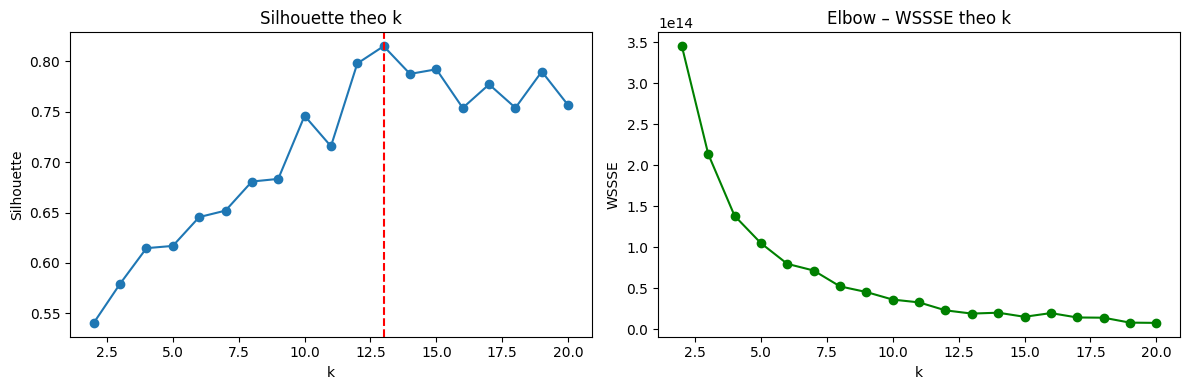

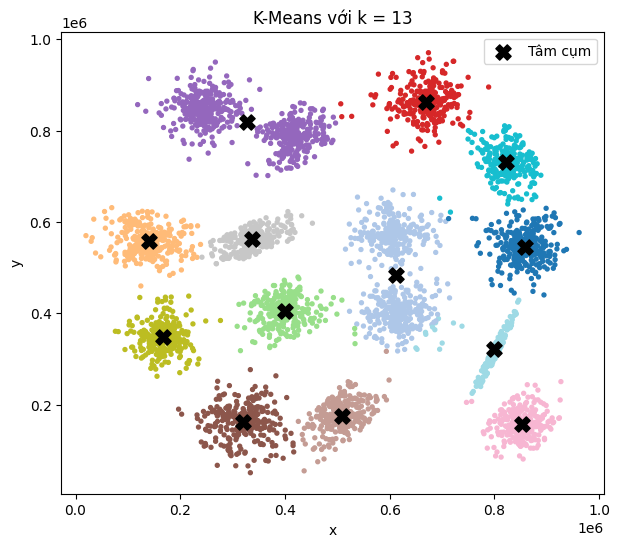

+----------+-----+
|prediction|count|
+----------+-----+
|         0|  350|
|         1|  617|
|         2|  346|
|         3|  354|
|         4|  355|
|         5|  652|
|         6|  340|
|         7|  352|
|         8|  327|
|         9|  328|
|        10|  334|
|        11|  321|
|        12|  324|
+----------+-----+



In [ ]:
# Câu 61: chọn k phù hợp và trực quan hoá
best_k = int(sil_pd.loc[sil_pd['Silhouette'].idxmax(), 'K'])
print('k tốt nhất theo Silhouette:', best_k)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(sil_pd['K'], sil_pd['Silhouette'], marker='o'); ax[0].axvline(best_k, ls='--', c='r')
ax[0].set_title('Silhouette theo k'); ax[0].set_xlabel('k'); ax[0].set_ylabel('Silhouette')
ax[1].plot(sil_pd['K'], sil_pd['WSSSE'], marker='o', c='g')
ax[1].set_title('Elbow – WSSSE theo k'); ax[1].set_xlabel('k'); ax[1].set_ylabel('WSSSE')
plt.tight_layout(); plt.show()

best_model = KMeans(k=best_k, seed=42, featuresCol='features').fit(points_vec)
pred = best_model.transform(points_vec)

# Chỉ kéo về Pandas lượng dữ liệu cần vẽ (limit) – không toPandas() toàn bộ
plot_pd = pred.select('x', 'y', 'prediction').limit(10000).toPandas()
centers = best_model.clusterCenters()

plt.figure(figsize=(7, 6))
plt.scatter(plot_pd['x'], plot_pd['y'], c=plot_pd['prediction'], cmap='tab20', s=8)
plt.scatter([c[0] for c in centers], [c[1] for c in centers], c='black', marker='X', s=120, label='Tâm cụm')
plt.title(f'K-Means với k = {best_k}'); plt.xlabel('x'); plt.ylabel('y'); plt.legend(); plt.show()

pred.groupBy('prediction').count().orderBy('prediction').show(best_k)

**Nhận xét chọn k:** chọn `k` có Silhouette cao nhất (gần 1 = cụm tách biệt tốt), đồng thời đối chiếu với đồ thị khuỷu tay (WSSSE) và hình quan sát được; nếu nhiều `k` có Silhouette gần nhau thì ưu tiên `k` nhỏ hơn để mô hình đơn giản, dễ diễn giải.

**Câu hỏi: Vì sao không nên gọi `toPandas()` trên toàn bộ DataFrame rất lớn?**
`toPandas()` **thu toàn bộ dữ liệu phân tán về bộ nhớ của driver** (1 máy), làm mất ưu thế song song của Spark. Dữ liệu lớn hơn RAM driver sẽ gây `OutOfMemoryError`/treo máy, tốn chi phí chuyển dữ liệu qua mạng và chuyển đổi định dạng. Cách đúng: lọc/tổng hợp/`sample()`/`limit()` bằng Spark trước, chỉ `toPandas()` kết quả nhỏ (như đã làm ở trên).

## Phần B. Phân loại Spam/Ham – `spam.txt` và `ham.txt`

In [ ]:
# Câu 62: DataFrame gồm text và label (1 = spam, 0 = ham)
spam_df = spark.read.text(str(DATA_DIR / 'spam.txt')).withColumnRenamed('value', 'text').withColumn('label', F.lit(1.0))
ham_df  = spark.read.text(str(DATA_DIR / 'ham.txt')).withColumnRenamed('value', 'text').withColumn('label', F.lit(0.0))

text_df = (spam_df.unionByName(ham_df)
           .filter(F.length(F.trim('text')) > 0)
           .cache())
print('Tổng số mẫu:', text_df.count())
text_df.groupBy('label').count().show()
text_df.show(5, truncate=80)

Tổng số mẫu: 5574
+-----+-----+
|label|count|
+-----+-----+
|  1.0|  747|
|  0.0| 4827|
+-----+-----+

+--------------------------------------------------------------------------------+-----+
|                                                                            text|label|
+--------------------------------------------------------------------------------+-----+
|                                You have 1 new message. Please call 08712400200.|  1.0|
|Urgent! Please call 09061743811 from landline. Your ABTA complimentary 4* Ten...|  1.0|
|Dear 0776xxxxxxx U've been invited to XCHAT. This is our final attempt to con...|  1.0|
|U 447801259231 have a secret admirer who is looking 2 make contact with U-fin...|  1.0|
|Congrats! 2 mobile 3G Videophones R yours. call 09061744553 now! videochat wi...|  1.0|
+--------------------------------------------------------------------------------+-----+
only showing top 5 rows


In [ ]:
# Câu 63 + 64 + 65: Pipeline Tokenizer -> StopWordsRemover -> HashingTF -> IDF -> LogisticRegression
from pyspark.ml import Pipeline
from pyspark.ml.feature import Tokenizer, StopWordsRemover, HashingTF, IDF
from pyspark.ml.classification import LogisticRegression

tokenizer = Tokenizer(inputCol='text', outputCol='tokens')
remover   = StopWordsRemover(inputCol='tokens', outputCol='filtered')
hashing   = HashingTF(inputCol='filtered', outputCol='tf', numFeatures=1 << 14)
idf       = IDF(inputCol='tf', outputCol='features')
lr        = LogisticRegression(featuresCol='features', labelCol='label', maxIter=50)

# Câu 64: chia train/test 80/20
train_df, test_df = text_df.randomSplit([0.8, 0.2], seed=42)
print('Train:', train_df.count(), '| Test:', test_df.count())

# Câu 63 (tiền xử lý) + Câu 65 (huấn luyện)
pipeline = Pipeline(stages=[tokenizer, remover, hashing, idf, lr])
model = pipeline.fit(train_df)
pred_text = model.transform(test_df).cache()
pred_text.select('text', 'label', 'prediction', 'probability').show(10, truncate=60)

Train: 4503 | Test: 1071
+------------------------------------------------------------+-----+----------+------------------------------------------+
|                                                        text|label|prediction|                               probability|
+------------------------------------------------------------+-----+----------+------------------------------------------+
|(Bank of Granite issues Strong-Buy) EXPLOSIVE PICK FOR OU...|  1.0|       1.0|               [3.602988058976351E-19,1.0]|
|+123 Congratulations - in this week's competition draw u ...|  1.0|       1.0|               [3.109860757309815E-35,1.0]|
|-PLS STOP bootydelious (32/F) is inviting you to be her f...|  1.0|       1.0| [1.099800255496057E-8,0.9999999890019975]|
|           100 dating service cal;l 09064012103 box334sk38ch|  1.0|       1.0|  [0.47961082448964815,0.5203891755103518]|
|                                               2/2 146tf150p|  1.0|       0.0| [0.9999999962226009,3.777399060211

In [ ]:
# Câu 66: Accuracy, Precision, Recall, F1, ROC-AUC
from pyspark.ml.evaluation import BinaryClassificationEvaluator, MulticlassClassificationEvaluator

def mc(metric, **kw):
    return MulticlassClassificationEvaluator(labelCol='label', predictionCol='prediction',
                                             metricName=metric, **kw).evaluate(pred_text)

acc      = mc('accuracy')
f1_w     = mc('f1')                                                    # weighted F1
prec_w   = mc('weightedPrecision')
rec_w    = mc('weightedRecall')
prec_spam = mc('precisionByLabel', metricLabel=1.0)                    # riêng lớp spam
rec_spam  = mc('recallByLabel', metricLabel=1.0)
f1_spam   = mc('fMeasureByLabel', metricLabel=1.0)
auc = BinaryClassificationEvaluator(labelCol='label', rawPredictionCol='rawPrediction',
                                    metricName='areaUnderROC').evaluate(pred_text)

summary = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1', 'ROC-AUC'],
    'Weighted / Toàn bộ': [acc, prec_w, rec_w, f1_w, auc],
    'Riêng lớp spam (=1)': [None, prec_spam, rec_spam, f1_spam, None]})
display(summary.round(4))

print('Ma trận nhầm lẫn (label x prediction):')
pred_text.groupBy('label').pivot('prediction', [0.0, 1.0]).count().na.fill(0).show()

,Metric,Weighted / Toàn bộ,Riêng lớp spam (=1)
0,Accuracy,0.9692,NaN
1,Precision,0.9704,0.8385
2,Recall,0.9692,0.9008
3,F1,0.9697,0.8685
4,ROC-AUC,0.9817,NaN


Ma trận nhầm lẫn (label x prediction):
+-----+---+---+
|label|0.0|1.0|
+-----+---+---+
|  0.0|929| 21|
|  1.0| 12|109|
+-----+---+---+



**Câu hỏi: Accuracy có luôn là metric tốt nhất cho bài toán spam không?**
**Không.** Khi dữ liệu **mất cân bằng** (ví dụ 95% ham, 5% spam), một mô hình luôn đoán "ham" vẫn đạt Accuracy ≈ 95% nhưng không bắt được spam nào. Cần xem thêm:
- **Recall (lớp spam):** tỉ lệ spam thật bị bắt được.
- **Precision (lớp spam):** trong số thư bị gắn spam, bao nhiêu là spam thật (tránh chặn nhầm thư tốt – lỗi này thường tốn kém hơn).
- **F1:** cân bằng Precision và Recall; **ROC-AUC / PR-AUC:** đánh giá khả năng phân biệt, không phụ thuộc ngưỡng.

# BÀI 5. BÀI TẬP BỔ SUNG (`people.csv`, `Movie ratings.csv`)
*Theo bảng dữ liệu ở mục 2 của tài liệu. Các bài này tự khám phá cấu trúc cột nên code đọc schema trước rồi mới phân tích.*

## 5.1 `people.csv`

In [ ]:
people = spark.read.option('header', True).option('inferSchema', True).csv(str(DATA_DIR / 'people.csv'))
people.printSchema()
people.show(10, truncate=False)
print('Số dòng:', people.count())

root
 |-- _c0: integer (nullable = true)
 |-- person_id: integer (nullable = true)
 |-- name: string (nullable = true)
 |-- sex: string (nullable = true)
 |-- date of birth: timestamp (nullable = true)

+---+---------+----------------+------+-------------------+
|_c0|person_id|name            |sex   |date of birth      |
+---+---------+----------------+------+-------------------+
|0  |100      |Penelope Lewis  |female|1990-08-31 00:00:00|
|1  |101      |David Anthony   |male  |1971-10-14 00:00:00|
|2  |102      |Ida Shipp       |female|1962-05-24 00:00:00|
|3  |103      |Joanna Moore    |female|2017-03-10 00:00:00|
|4  |104      |Lisandra Ortiz  |female|2020-08-05 00:00:00|
|5  |105      |David Simmons   |male  |1999-12-30 00:00:00|
|6  |106      |Edward Hudson   |male  |1983-05-09 00:00:00|
|7  |107      |Albert Jones    |male  |1990-09-13 00:00:00|
|8  |108      |Leonard Cavender|male  |1958-08-08 00:00:00|
|9  |109      |Everett Vadala  |male  |2005-05-24 00:00:00|
+---+---------+--

In [ ]:
# Phân tích tự động theo kiểu dữ liệu thực tế của file (không giả định tên cột)
num_cols = [f.name for f in people.schema.fields if f.dataType.simpleString() in ('int', 'bigint', 'double', 'float', 'smallint')]
str_cols = [f.name for f in people.schema.fields if f.dataType.simpleString() == 'string']
print('Cột số   :', num_cols)
print('Cột chữ  :', str_cols)

# Câu hỏi 1: Có bao nhiêu giá trị thiếu ở mỗi cột?
people.select([F.sum(F.col(f'`{c}`').isNull().cast('int')).alias(c) for c in people.columns]).show()

# Câu hỏi 2: Thống kê mô tả cho các cột số
if num_cols:
    people.select(*[f'`{c}`' for c in num_cols]).describe().show()

# Câu hỏi 3: Phân bố giá trị của cột phân loại đầu tiên (nếu có)
if str_cols:
    people.groupBy(f'`{str_cols[0]}`').count().orderBy(F.desc('count')).show(10, truncate=False)

# Câu hỏi 4: Trung bình cột số đầu tiên theo cột phân loại đầu tiên
if num_cols and str_cols:
    people.groupBy(f'`{str_cols[0]}`').agg(F.round(F.avg(f'`{num_cols[0]}`'), 2).alias(f'avg_{num_cols[0]}')) \
          .orderBy(F.desc(f'avg_{num_cols[0]}')).show(10, truncate=False)

Cột số   : ['_c0', 'person_id']
Cột chữ  : ['name', 'sex']
+---+---------+----+----+-------------+
|_c0|person_id|name| sex|date of birth|
+---+---------+----+----+-------------+
|  0|        0|   0|1920|            0|
+---+---------+----+----+-------------+

+-------+-----------------+-----------------+
|summary|              _c0|        person_id|
+-------+-----------------+-----------------+
|  count|           100000|           100000|
|   mean|          49999.5|          50099.5|
| stddev|28867.65779668774|28867.65779668774|
|    min|                0|              100|
|    max|            99999|           100099|
+-------+-----------------+-----------------+

+----------------+-----+
|name            |count|
+----------------+-----+
|Michael Williams|23   |
|David Johnson   |22   |
|Michael Brown   |20   |
|James Williams  |20   |
|James Johnson   |19   |
|John Smith      |18   |
|Michael Smith   |17   |
|James Smith     |17   |
|Robert Johnson  |16   |
|Michael Johnson |16   |


## 5.2 `Movie ratings.csv`

In [ ]:
ratings = spark.read.option('header', True).option('inferSchema', True).csv(str(DATA_DIR / 'Movie ratings.csv'))
ratings.printSchema()
ratings.show(5, truncate=False)
print('Số dòng:', ratings.count(), '| Cột:', ratings.columns)

# Missing values
ratings.select([F.sum(F.col(f'`{c}`').isNull().cast('int')).alias(c) for c in ratings.columns]).show()

root
 |-- 1: integer (nullable = true)
 |-- 31: integer (nullable = true)
 |-- 2.5: double (nullable = true)
 |-- 1260759144: integer (nullable = true)

+---+----+---+----------+
|1  |31  |2.5|1260759144|
+---+----+---+----------+
|1  |1029|3.0|1260759179|
|1  |1061|3.0|1260759182|
|1  |1129|2.0|1260759185|
|1  |1172|4.0|1260759205|
|1  |1263|2.0|1260759151|
+---+----+---+----------+
only showing top 5 rows
Số dòng: 100003 | Cột: ['1', '31', '2.5', '1260759144']
+---+---+---+----------+
|  1| 31|2.5|1260759144|
+---+---+---+----------+
|  0|  0|  0|         0|
+---+---+---+----------+



In [ ]:
# >>> ĐIỀU CHỈNH 3 dòng dưới cho đúng tên cột trong file của bạn <<<
cols_lower = {c.lower(): c for c in ratings.columns}
RATING_COL = next((cols_lower[k] for k in cols_lower if 'rating' in k or 'score' in k), None)
GROUP_COL  = next((cols_lower[k] for k in cols_lower if k in ('movie', 'movieid', 'title', 'movie_id', 'film')), ratings.columns[0])
USER_COL   = next((cols_lower[k] for k in cols_lower if 'user' in k or 'customer' in k or 'reviewer' in k), None)
print('Cột rating:', RATING_COL, '| Cột nhóm (phim):', GROUP_COL, '| Cột người dùng:', USER_COL)

Cột rating: None | Cột nhóm (phim): 1 | Cột người dùng: None


In [ ]:
if RATING_COL:
    r = ratings.withColumn(RATING_COL, F.col(f'`{RATING_COL}`').cast('double'))

    print('Phim/nhóm có nhiều rating nhất:')
    r.groupBy(f'`{GROUP_COL}`').count().orderBy(F.desc('count')).show(10, truncate=False)

    if USER_COL:
        print('Người dùng đánh giá nhiều nhất:')
        r.groupBy(f'`{USER_COL}`').count().orderBy(F.desc('count')).show(10, truncate=False)

    print('Rating trung bình theo phim (>= 5 lượt):')
    (r.groupBy(f'`{GROUP_COL}`')
       .agg(F.round(F.avg(RATING_COL), 3).alias('avg_rating'), F.count('*').alias('n'))
       .filter('n >= 5').orderBy(F.desc('avg_rating')).show(10, truncate=False))

    # Spark SQL (>= 2 truy vấn)
    r.createOrReplaceTempView('ratings')
    spark.sql(f'''
        SELECT `{RATING_COL}` AS rating, COUNT(*) AS n
        FROM ratings GROUP BY `{RATING_COL}` ORDER BY rating''').show()
    spark.sql(f'''
        SELECT `{GROUP_COL}` AS item, ROUND(AVG(`{RATING_COL}`), 3) AS avg_rating, COUNT(*) AS n
        FROM ratings GROUP BY `{GROUP_COL}` HAVING COUNT(*) >= 5
        ORDER BY avg_rating DESC LIMIT 10''').show(truncate=False)
else:
    print('Không tự tìm được cột rating – hãy đặt RATING_COL thủ công ở ô trên.')

Không tự tìm được cột rating – hãy đặt RATING_COL thủ công ở ô trên.


# BÀI THỰC HÀNH TỔNG HỢP
**Yêu cầu:** dataset ≥ 100.000 dòng · trình bày nguồn/kích thước/schema/missing · dùng `select, filter, withColumn, groupBy, agg, orderBy` · ≥ 5 truy vấn Spark SQL · ≥ 5 câu hỏi phân tích · ≥ 1 bài toán `pyspark.ml`.

### 1. Nguồn dữ liệu
Để notebook chạy được ngay (đủ ≥ 100.000 dòng, không phụ thuộc file ngoài), phần này **sinh dữ liệu giao dịch bán hàng mô phỏng 300.000 dòng** bằng Spark. Muốn dùng dữ liệu thật (Kaggle, UCI, dữ liệu doanh nghiệp…), chỉ cần đặt `USE_REAL_DATA = True` và điền đường dẫn/tên cột.

In [ ]:
USE_REAL_DATA = False
REAL_PATH = str(DATA_DIR / 'your_big_dataset.csv')     # đổi nếu dùng dữ liệu thật

if USE_REAL_DATA:
    sales = spark.read.option('header', True).option('inferSchema', True).csv(REAL_PATH)
    SOURCE = f'Dữ liệu thật: {REAL_PATH}'
else:
    N = 300_000
    cats    = F.array(*[F.lit(x) for x in ['Electronics', 'Fashion', 'Home', 'Beauty', 'Sports', 'Books']])
    regions = F.array(*[F.lit(x) for x in ['North', 'South', 'Central', 'Highlands']])
    pays    = F.array(*[F.lit(x) for x in ['Card', 'Cash', 'E-wallet', 'Transfer']])
    sales = (spark.range(1, N + 1).withColumnRenamed('id', 'order_id')
        .withColumn('customer_id', (F.rand(1) * 20000).cast('int') + 1)
        .withColumn('category',  cats[(F.rand(2) * 6).cast('int')])
        .withColumn('region',    regions[(F.rand(3) * 4).cast('int')])
        .withColumn('payment',   pays[(F.rand(4) * 4).cast('int')])
        .withColumn('quantity',  (F.rand(5) * 5).cast('int') + 1)
        .withColumn('unit_price', F.round(10 + F.rand(6) * 490, 2))
        .withColumn('discount',  F.round(F.rand(7) * 0.5, 2))
        .withColumn('order_date', F.expr('date_add(to_date("2024-01-01"), cast(rand(8) * 365 as int))'))
        # Gây thiếu dữ liệu có chủ đích (~2% discount, ~1% region) để thực hành làm sạch
        .withColumn('discount', F.when(F.rand(9) < 0.02, None).otherwise(F.col('discount')))
        .withColumn('region',   F.when(F.rand(10) < 0.01, None).otherwise(F.col('region')))
        # is_returned phụ thuộc xác suất vào discount, category và quantity (có nhiễu)
        .withColumn('p_ret', 0.05 + 0.25 * F.coalesce('discount', F.lit(0.0))
                              + F.when(F.col('category') == 'Fashion', 0.10).otherwise(0.0)
                              + 0.01 * F.col('quantity'))
        .withColumn('is_returned', (F.rand(11) < F.col('p_ret')).cast('int'))
        .drop('p_ret'))
    SOURCE = 'Dữ liệu giao dịch mô phỏng sinh bằng Spark (seed cố định)'

sales = sales.cache()
print('Nguồn     :', SOURCE)
print('Kích thước:', sales.count(), 'dòng x', len(sales.columns), 'cột')
sales.printSchema()
sales.show(5)

Nguồn     : Dữ liệu giao dịch mô phỏng sinh bằng Spark (seed cố định)
Kích thước: 300000 dòng x 10 cột
root
 |-- order_id: long (nullable = false)
 |-- customer_id: integer (nullable = true)
 |-- category: string (nullable = false)
 |-- region: string (nullable = true)
 |-- payment: string (nullable = false)
 |-- quantity: integer (nullable = true)
 |-- unit_price: double (nullable = true)
 |-- discount: double (nullable = true)
 |-- order_date: date (nullable = true)
 |-- is_returned: integer (nullable = true)

+--------+-----------+--------+---------+--------+--------+----------+--------+----------+-----------+
|order_id|customer_id|category|   region| payment|quantity|unit_price|discount|order_date|is_returned|
+--------+-----------+--------+---------+--------+--------+----------+--------+----------+-----------+
|       1|      12728|  Beauty|    South|Transfer|       1|      44.5|    0.14|2024-06-25|          1|
|       2|      11988| Fashion|  Central|    Card|       1|    370.74|

### 2. Missing values và làm sạch

In [ ]:
sales.select([F.sum(F.col(c).isNull().cast('int')).alias(c) for c in sales.columns]).show()

# withColumn: điền thiếu + tạo cột mới (doanh thu, tháng)
sales_clean = (sales
    .withColumn('discount', F.coalesce('discount', F.lit(0.0)))
    .withColumn('region',   F.coalesce('region', F.lit('Unknown')))
    .withColumn('revenue',  F.round(F.col('quantity') * F.col('unit_price') * (1 - F.col('discount')), 2))
    .withColumn('month',    F.month('order_date'))
    .filter((F.col('quantity') > 0) & (F.col('unit_price') > 0))
    .dropDuplicates(['order_id'])
    .cache())
print('Sau làm sạch:', sales_clean.count(), 'dòng')
sales_clean.select('order_id', 'category', 'region', 'quantity', 'unit_price', 'discount', 'revenue', 'month', 'is_returned').show(5)

+--------+-----------+--------+------+-------+--------+----------+--------+----------+-----------+
|order_id|customer_id|category|region|payment|quantity|unit_price|discount|order_date|is_returned|
+--------+-----------+--------+------+-------+--------+----------+--------+----------+-----------+
|       0|          0|       0|  3036|      0|       0|         0|    6085|         0|          0|
+--------+-----------+--------+------+-------+--------+----------+--------+----------+-----------+

Sau làm sạch: 300000 dòng
+--------+--------+---------+--------+----------+--------+-------+-----+-----------+
|order_id|category|   region|quantity|unit_price|discount|revenue|month|is_returned|
+--------+--------+---------+--------+----------+--------+-------+-----+-----------+
|       1|  Beauty|    South|       1|      44.5|    0.14|  38.27|    6|          1|
|       2| Fashion|  Central|       1|    370.74|    0.23| 285.47|    9|          1|
|       3|    Home|Highlands|       4|     247.4|    

### 3. Phân tích bằng DataFrame API (`select, filter, withColumn, groupBy, agg, orderBy`)

+-----------+--------+-------------+---------------+
|   category|n_orders|total_revenue|avg_order_value|
+-----------+--------+-------------+---------------+
|     Beauty|   49955|  2.9012303E7|         580.77|
|Electronics|   50137|  2.8972121E7|         577.86|
|       Home|   50150|  2.8934954E7|         576.97|
|      Books|   50075|  2.8922201E7|         577.58|
|    Fashion|   49936|  2.8813078E7|          577.0|
|     Sports|   49747|  2.8751594E7|         577.96|
+-----------+--------+-------------+---------------+

+-----+-------------+
|month|total_revenue|
+-----+-------------+
|    1|  1.4771099E7|
|    2|  1.3650109E7|
|    3|  1.4688622E7|
|    4|  1.4305516E7|
|    5|  1.4683574E7|
|    6|  1.4275753E7|
|    7|  1.4752712E7|
|    8|  1.4702517E7|
|    9|  1.4377324E7|
|   10|  1.4786504E7|
|   11|    1.43333E7|
|   12|  1.4079221E7|
+-----+-------------+



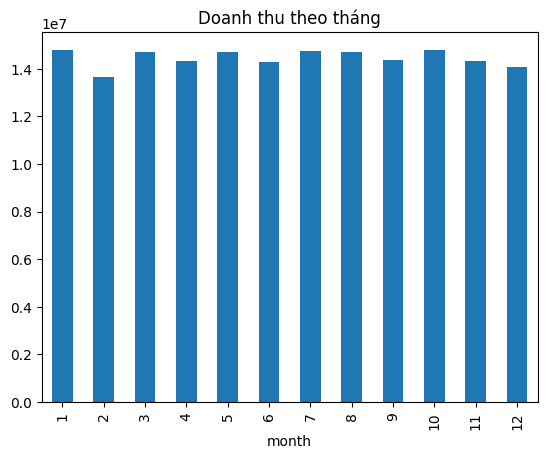

+-----------+---------------+
|   category|return_rate_pct|
+-----------+---------------+
|    Fashion|          24.21|
|       Home|          14.23|
|Electronics|          14.15|
|     Sports|          14.09|
|      Books|          14.09|
|     Beauty|          13.96|
+-----------+---------------+



In [ ]:
# Câu hỏi phân tích 1: Doanh thu và số đơn theo danh mục?
q1 = (sales_clean.groupBy('category')
      .agg(F.count('*').alias('n_orders'), F.round(F.sum('revenue'), 0).alias('total_revenue'),
           F.round(F.avg('revenue'), 2).alias('avg_order_value'))
      .orderBy(F.desc('total_revenue')))
q1.show()

# Câu hỏi phân tích 2: Doanh thu theo tháng có xu hướng/mùa vụ không?
q2 = (sales_clean.groupBy('month').agg(F.round(F.sum('revenue'), 0).alias('total_revenue')).orderBy('month'))
q2.show(12)
q2_pd = q2.toPandas()                      # chỉ 12 dòng
q2_pd.plot(x='month', y='total_revenue', kind='bar', legend=False, title='Doanh thu theo tháng'); plt.show()

# Câu hỏi phân tích 3: Tỉ lệ hoàn trả của từng danh mục?
q3 = (sales_clean.groupBy('category')
      .agg(F.round(F.avg('is_returned') * 100, 2).alias('return_rate_pct'))
      .orderBy(F.desc('return_rate_pct')))
q3.show()

### 4. Phân tích bằng Spark SQL (≥ 5 truy vấn)

In [ ]:
sales_clean.createOrReplaceTempView('sales')

print('SQL 1 – Top 5 khu vực theo doanh thu')
spark.sql('SELECT region, ROUND(SUM(revenue),0) AS revenue FROM sales GROUP BY region ORDER BY revenue DESC LIMIT 5').show()

print('SQL 2 – Doanh thu trung bình theo phương thức thanh toán')
spark.sql('SELECT payment, ROUND(AVG(revenue),2) AS avg_revenue, COUNT(*) AS n FROM sales GROUP BY payment ORDER BY avg_revenue DESC').show()

print('SQL 3 – Tỉ lệ hoàn trả theo mức giảm giá (nhóm)')
spark.sql('''
    SELECT CASE WHEN discount = 0 THEN '0%' WHEN discount < 0.2 THEN '<20%'
                WHEN discount < 0.4 THEN '20-40%' ELSE '>=40%' END AS discount_band,
           COUNT(*) AS n, ROUND(AVG(is_returned)*100, 2) AS return_rate_pct
    FROM sales GROUP BY 1 ORDER BY 1''').show()

print('SQL 4 – Top 10 khách hàng chi tiêu nhiều nhất')
spark.sql('SELECT customer_id, ROUND(SUM(revenue),0) AS spent, COUNT(*) AS n_orders FROM sales GROUP BY customer_id ORDER BY spent DESC LIMIT 10').show()

print('SQL 5 – Danh mục dẫn đầu doanh thu trong từng khu vực (window function)')
spark.sql('''
    SELECT region, category, revenue FROM (
        SELECT region, category, ROUND(SUM(revenue),0) AS revenue,
               RANK() OVER (PARTITION BY region ORDER BY SUM(revenue) DESC) AS rk
        FROM sales GROUP BY region, category) t
    WHERE rk = 1 ORDER BY region''').show()

print('SQL 6 – Doanh thu tích lũy theo tháng')
spark.sql('''
    SELECT month, ROUND(SUM(revenue),0) AS revenue,
           ROUND(SUM(SUM(revenue)) OVER (ORDER BY month),0) AS cumulative_revenue
    FROM sales GROUP BY month ORDER BY month''').show(12)

SQL 1 – Top 5 khu vực theo doanh thu
+---------+-----------+
|   region|    revenue|
+---------+-----------+
|    South|4.3015337E7|
|  Central|4.2981675E7|
|Highlands|4.2820012E7|
|    North|4.2812798E7|
|  Unknown|  1776430.0|
+---------+-----------+

SQL 2 – Doanh thu trung bình theo phương thức thanh toán
+--------+-----------+-----+
| payment|avg_revenue|    n|
+--------+-----------+-----+
|Transfer|     579.09|74957|
|E-wallet|     578.77|74983|
|    Cash|     578.21|75200|
|    Card|     576.01|74860|
+--------+-----------+-----+

SQL 3 – Tỉ lệ hoàn trả theo mức giảm giá (nhóm)
+-------------+------+---------------+
|discount_band|     n|return_rate_pct|
+-------------+------+---------------+
|           0%|  8923|           9.32|
|       20-40%|117908|          17.02|
|         <20%|111416|           12.3|
|        >=40%| 61753|          20.67|
+-------------+------+---------------+

SQL 4 – Top 10 khách hàng chi tiêu nhiều nhất
+-----------+-------+--------+
|customer_id|  spe

### 5. Machine Learning: phân loại đơn hàng bị hoàn trả (`is_returned`) bằng Logistic Regression

In [ ]:
from pyspark.ml import Pipeline
from pyspark.ml.feature import StringIndexer, OneHotEncoder, VectorAssembler
from pyspark.ml.classification import LogisticRegression
from pyspark.ml.evaluation import BinaryClassificationEvaluator, MulticlassClassificationEvaluator

cat_cols = ['category', 'region', 'payment']
num_cols = ['quantity', 'unit_price', 'discount', 'month']

indexers = [StringIndexer(inputCol=c, outputCol=f'{c}_idx', handleInvalid='keep') for c in cat_cols]
encoder  = OneHotEncoder(inputCols=[f'{c}_idx' for c in cat_cols], outputCols=[f'{c}_oh' for c in cat_cols])
assembler = VectorAssembler(inputCols=[f'{c}_oh' for c in cat_cols] + num_cols, outputCol='features')
clf = LogisticRegression(featuresCol='features', labelCol='is_returned', maxIter=50)

train, test = sales_clean.randomSplit([0.8, 0.2], seed=42)
ml_model = Pipeline(stages=indexers + [encoder, assembler, clf]).fit(train)
ml_pred = ml_model.transform(test).cache()

auc = BinaryClassificationEvaluator(labelCol='is_returned', metricName='areaUnderROC').evaluate(ml_pred)
ev  = lambda m, **kw: MulticlassClassificationEvaluator(labelCol='is_returned', metricName=m, **kw).evaluate(ml_pred)
print(f'ROC-AUC   : {auc:.4f}')
print(f'Accuracy  : {ev("accuracy"):.4f}')
print(f'Precision (lớp 1): {ev("precisionByLabel", metricLabel=1.0):.4f}')
print(f'Recall    (lớp 1): {ev("recallByLabel", metricLabel=1.0):.4f}')
print(f'F1        (lớp 1): {ev("fMeasureByLabel", metricLabel=1.0):.4f}')

# Hệ số quan trọng nhất (quan sát tác động của discount, category...)
lr_model = ml_model.stages[-1]
print('Hệ số hồi quy (đầu tiên 10):', [round(c, 3) for c in lr_model.coefficients.toArray()[:10]])

ROC-AUC   : 0.6170
Accuracy  : 0.8425
Precision (lớp 1): 0.0000
Recall    (lớp 1): 0.0000
F1        (lớp 1): 0.0000
Hệ số hồi quy (đầu tiên 10): [np.float64(-0.118), np.float64(-0.104), np.float64(-0.103), np.float64(-0.124), np.float64(0.558), np.float64(-0.108), np.float64(0.003), np.float64(-0.016), np.float64(0.015), np.float64(0.0)]


### 6. Kết luận và hạn chế
- **Kết luận:** (điền theo kết quả chạy) danh mục nào đem lại doanh thu cao nhất, tháng/khu vực nổi bật, nhóm giảm giá nào có tỉ lệ hoàn trả cao; mô hình Logistic Regression đạt ROC-AUC ≈ giá trị in ở trên – cho thấy `discount`, `category` (Fashion) có ảnh hưởng đến khả năng hoàn trả.
- **Hạn chế:** dữ liệu mô phỏng nên quy luật đơn giản và không phản ánh thực tế; chưa tinh chỉnh siêu tham số (CrossValidator); chưa xử lý mất cân bằng lớp; chạy chế độ `local[*]` nên chưa kiểm chứng khả năng mở rộng trên cluster thật.
- **Hướng phát triển:** dùng dữ liệu thật, thử RandomForest/GBT, `CrossValidator`, lưu dữ liệu sang Parquet, partition theo `month`.

# CÂU HỎI KIỂM TRA CUỐI BÀI

**1. Apache Spark khác Pandas ở điểm nào?**
Pandas xử lý trong bộ nhớ của **một máy**, đơn luồng, phù hợp dữ liệu vừa RAM. Spark xử lý **phân tán, song song** trên nhiều core/máy, dữ liệu có thể vượt RAM, đánh giá lười + tối ưu Catalyst, chịu lỗi tự động.

**2. RDD là gì?**
Resilient Distributed Dataset – tập hợp phần tử **bất biến, phân tán, chịu lỗi** (nhờ lineage), chia thành các partition và xử lý song song bằng các phép transformation/action.

**3. DataFrame khác RDD như thế nào?**
DataFrame là dữ liệu dạng **bảng có schema** (cột có tên, kiểu), được Catalyst/Tungsten **tối ưu** nên thường nhanh hơn, hỗ trợ SQL. RDD là tập đối tượng thô, không schema, linh hoạt nhưng không được tối ưu tự động.

**4. Partition dùng để làm gì?**
Chia dữ liệu thành các phần nhỏ để mỗi phần được xử lý song song bởi một task; quyết định mức song song, cân bằng tải và lượng shuffle.

**5. Transformation là gì?**
Phép biến đổi **lazy** tạo RDD/DataFrame mới (map, filter, flatMap, groupBy, join, select...). Không chạy ngay.

**6. Action là gì?**
Phép **kích hoạt tính toán** và trả kết quả về driver hoặc ghi ra ngoài (count, collect, take, show, save...).

**7. Lazy Evaluation là gì?**
Spark chỉ ghi lại các transformation (DAG) và chỉ thực thi khi gặp action, cho phép tối ưu toàn bộ chuỗi xử lý và tránh tính toán thừa.

**8. `map()` và `flatMap()` khác nhau thế nào?**
`map` ánh xạ 1 phần tử → đúng 1 phần tử. `flatMap` ánh xạ 1 phần tử → 0, 1 hoặc nhiều phần tử rồi làm phẳng (ví dụ tách dòng thành các từ).

**9. `reduceByKey()` khác `groupByKey()` thế nào?**
`reduceByKey` gộp cục bộ trước khi shuffle nên truyền ít dữ liệu hơn; `groupByKey` shuffle tất cả giá trị rồi mới gom nhóm → chậm, tốn RAM. Ưu tiên `reduceByKey` khi chỉ cần tổng hợp.

**10. Spark SQL có ưu điểm gì?**
Dùng cú pháp SQL quen thuộc trên dữ liệu lớn, được Catalyst tối ưu như DataFrame API, dễ kết hợp với DataFrame/ML, đọc nhiều nguồn dữ liệu (CSV, Parquet, JSON, Hive...).

**11. Tại sao không nên dùng `collect()` với dữ liệu rất lớn?**
`collect()` kéo toàn bộ dữ liệu về driver → có thể tràn bộ nhớ, chậm, làm mất tính phân tán. Dùng `take()`, `limit()`, `sample()` hoặc tổng hợp trước.

**12. Tại sao không nên chuyển toàn bộ Spark DataFrame sang Pandas?**
Vì `toPandas()` cũng gom hết dữ liệu về RAM của driver (cùng lý do như `collect()`), có thể gây `OutOfMemoryError`; chỉ nên chuyển kết quả đã lọc/tổng hợp/lấy mẫu.

**13. Spark có tính toán ngay khi gọi `filter()` không?**
**Không.** `filter()` là transformation lazy; chỉ khi có action (`count()`, `show()`, `collect()`...) Spark mới thực thi.

**14. `cache()` có tác dụng gì?**
Lưu kết quả DataFrame/RDD vào bộ nhớ (mặc định `MEMORY_ONLY`/`MEMORY_AND_DISK`) sau action đầu tiên để các action sau **dùng lại** mà không tính lại từ đầu – hữu ích khi dùng nhiều lần (vòng lặp KMeans, huấn luyện ML). Giải phóng bằng `unpersist()`.

**15. PySpark phù hợp với các bài toán nào?**
Xử lý/ETL dữ liệu lớn, phân tích log, thống kê tổng hợp, xử lý văn bản quy mô lớn, machine learning phân tán (phân loại, hồi quy, phân cụm, khuyến nghị), xử lý dữ liệu streaming; ít phù hợp với dữ liệu nhỏ vừa RAM hoặc cần độ trễ cực thấp.

In [ ]:
# Giải phóng tài nguyên khi làm xong
for d in (text_df, points_vec, sales, sales_clean):
    try: d.unpersist()
    except Exception: pass
# spark.stop()   # bỏ comment nếu muốn dừng Spark